# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and crest for k-means clustering and thresholding. The test data are generated by solving GA bubble model.

In [2]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [3]:

%matplotlib inline
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
# from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats
from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Parameters

Specify parameters for synthetic data and wavelet transform

In [4]:
pac = -5E5                     # the amplitude of the sine wave in Pa
frequency = 5*1E5             # insonation frequency (Hz)
no_cycle = 20                   # no. of cycles of the sine wave
sampling_rate = frequency*20              # sampling rate to generate the time vector
tstep = 1./sampling_rate
tmax = no_cycle/frequency 
time = np.arange(0.,tmax,tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db10"
levels = 8
mode = "symmetric"

fft_lim = 10*frequency  # increase value to view more of the fft plots

### Generating acoustic emission data by solving Gilmore-Akulichev model

Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). Plot the data with its FFT. 

In [5]:
# generate sound wave

BD_obj = BD(R_init,Rdot_init,frequency,pac,time,tstep)
BD_obj.solver()
BD_obj.calculate_p_radiated(r_measure = r_measure)

data = BD_obj.p_radiated
time = BD_obj.time

signal_length = len(data)

# data += sd.noise(std_noise, duration=time[-1]+tstep, sampling_rate=sampling_rate)

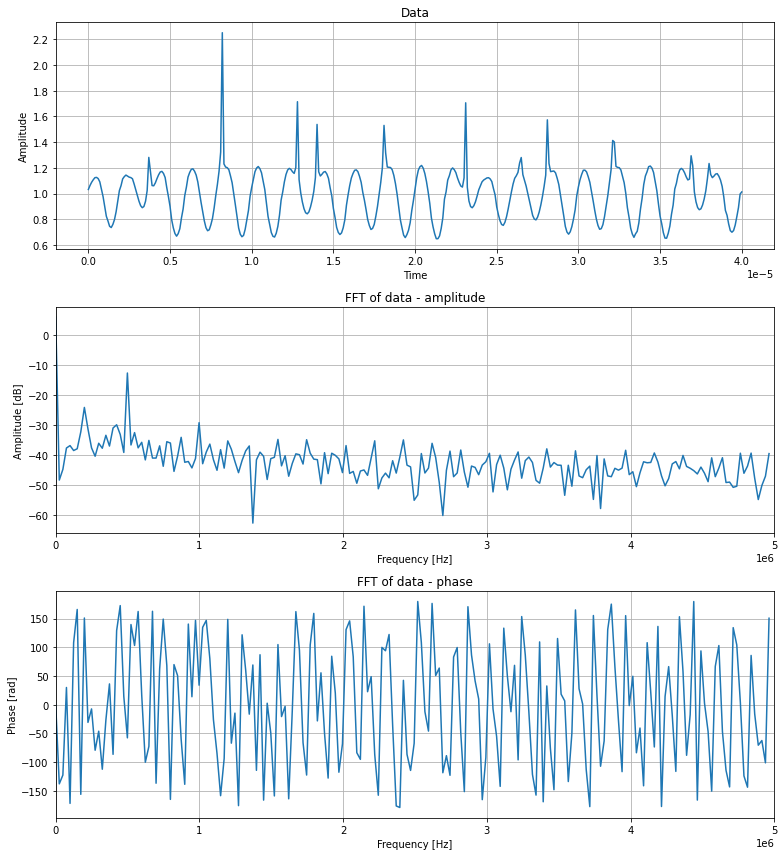

In [6]:
fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].plot(
    freq,
    20*np.log10(np.abs(fft_data))
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [dB]")
ax[1].set_xlim(0, fft_lim)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, fft_lim)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

Wavelet transform

In [7]:
import pandas as pd

# Set display options
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns


# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# calculate energy, kurtosis, and crest factor of reconstructed signals
wpt_df = pd.DataFrame(
    columns=[
        "node",
        "inverse",
        "fft",
        "energy",
        "kurtosis",
        "crest",
        "entropy",
        "skewness",
    ]
)

total_energy = stats.calc_energy(data)

# reconstruct each node separately
counter = 0
for node in tr_ob.get_level(level=levels, order="freq"):
    node_data = node.data  # coefficients from transform

    # calculate inverse transform
    inverse = inv.inv_dwpt(tr_ob, level=levels,nodes=node)
    inverse_signal_length = len(inverse)

    # calculate fft of inverse
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )

    # calculate statistical measures
    entropy_node = stats.calc_entropy(node.energy, total_energy)
    kurtosis = stats.calc_kurtosis(node_data)
    skewness = stats.calc_skewness(node_data)
    crest = stats.calc_crest_factor(node_data)

    wpt_df.loc[counter, "node"] = node
    wpt_df.loc[counter, "inverse"] = inverse
    wpt_df.loc[counter, "fft"] = fft
    wpt_df.loc[counter, "energy"] = node.energy
    wpt_df.loc[counter, "kurtosis"] = kurtosis
    wpt_df.loc[counter, "crest"] = crest
    wpt_df.loc[counter, "entropy"] = entropy_node
    wpt_df.loc[counter, "skewness"] = skewness
    counter += 1

tr_ob.info(level=levels, order="freq").head()

,node number,energy,kurtosis,crest factor,skewness,frequency range
0,0,0.013264,2.737354,-6.359097,0.829184,"(0.0, 1.953e4)"
1,1,0.005651,2.078651,-1.413786,0.015959,"(1.953e4, 3.906e4)"
2,3,0.005771,1.802072,-1.758961,-0.413902,"(3.906e4, 5.859e4)"
3,2,0.035449,2.027275,-1.107489,0.070297,"(5.859e4, 7.812e4)"
4,6,0.028086,1.872813,-2.057811,0.257754,"(7.812e4, 9.766e4)"


In [8]:
wpt_df.head()

,node,inverse,fft,energy,kurtosis,crest,entropy,skewness
0,<wavelet_transform.wpt.transform_object.Node o...,"[0.9830270489024968, 0.9831306942565762, 0.983...","[(1.9853319188063674+3.5023245041167657e-17j),...",0.013264,2.737354,-6.359097,0.528459,0.829184
1,<wavelet_transform.wpt.transform_object.Node o...,"[-0.002898940942800634, -0.002813757884840884,...",[(0.0005685433492160759+4.109694020393932e-20j...,0.005651,2.078651,-1.413786,0.400478,0.015959
2,<wavelet_transform.wpt.transform_object.Node o...,"[-0.0004459957846260301, -0.000298704921897041...",[(0.0014227560009210719+2.422556475179581e-19j...,0.005771,1.802072,-1.758961,0.404575,-0.413902
3,<wavelet_transform.wpt.transform_object.Node o...,"[0.003699128351156838, 0.0035181320744368857, ...",[(0.0016700276762727198+6.921589929084517e-20j...,0.035449,2.027275,-1.107489,0.145215,0.070297
4,<wavelet_transform.wpt.transform_object.Node o...,"[0.005880468118768929, 0.006527312827274604, 0...",[(0.0012463856835553018+1.8385473249130747e-19...,0.028086,1.872813,-2.057811,0.352816,0.257754


<AxesSubplot:xlabel='entropy', ylabel='crest'>

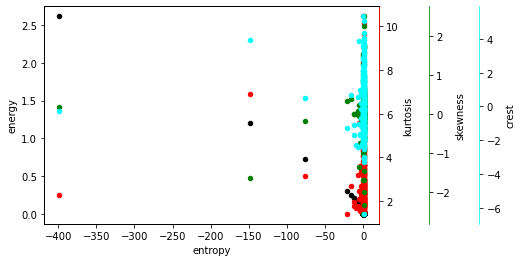

In [9]:
ax_df1 = wpt_df.plot.scatter(x='entropy',y='energy',c='black')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.0))
ax_df2.spines['right'].set_edgecolor('red')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='kurtosis',c='red')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.15))
ax_df2.spines['right'].set_edgecolor('green')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='skewness',c='green')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.3))
ax_df2.spines['right'].set_edgecolor('cyan')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='crest',c='cyan')

<AxesSubplot:xlabel='kurtosis', ylabel='crest'>

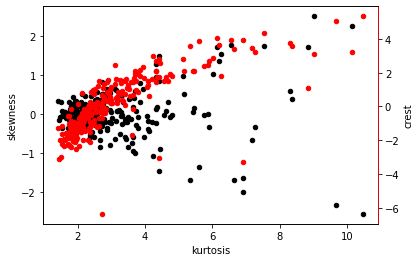

In [10]:
ax_df1 = wpt_df.plot.scatter(x='kurtosis',y='skewness',c='black')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.0))
ax_df2.spines['right'].set_edgecolor('red')
wpt_df.plot.scatter(ax=ax_df2, x='kurtosis',y='crest',c='red')

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

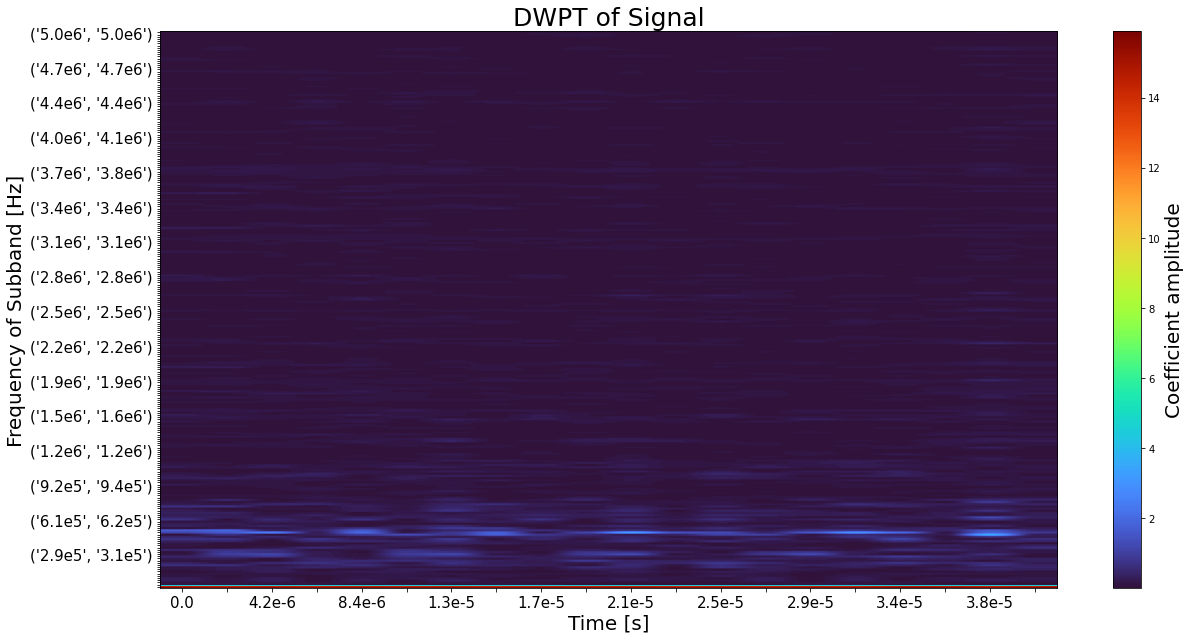

In [11]:
plot.heisenberg(tr_ob, max(time))

<AxesSubplot:>

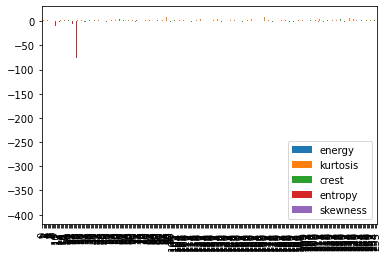

In [12]:
wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [13]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, labels, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)


In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
classifying_metrics = ["entropy", "kurtosis", "crest"]
data_train = wpt_df[classifying_metrics]

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 3
kmeans_params = {"init":"k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"elkan",
    }

kmeans = KMeans(n_clusters=no_clusters,**kmeans_params)
data_train_predict = kmeans.fit_predict(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
print(kmeans.cluster_centers_)
print(kmeans.n_iter_)
# centers = kmeans.cluster_centers_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

[[  0.02344993   1.25675915   1.28253856]
 [  0.06966463  -0.44522459  -0.45584761]
 [-14.66809501  -0.50064097  -0.23073258]]
4


In [15]:
data_train_predict

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 2, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0])

In [16]:
cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [ 67 188   1]
cluster IDs: [0 1 2]


In [17]:
fit_and_evaluate(kmeans, data_train_normalised, labels, name='wpt data')

clustering done in 0.03 ± 0.01 s 
Homogeneity: 0.742 ± 0.000
Completeness: 0.801 ± 0.000
V-measure: 0.770 ± 0.000
Adjusted Rand-Index: 0.840 ± 0.000
Silhouette Coefficient: 0.565 ± 0.000


3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### Reassigning Groups

Post-hoc reassignment of groups based on the energy and kurtosis of their clusters.

In [23]:
def assign_labels_entropy(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with
    lowest entropy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by entropy, lowest entropy is highest group number
    sort_by_entropy = np.argsort(centers[:, 0])[::-1]  # assumes entropy is in 1st position

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest,  # delete lowest entropy group form kurtosis
        np.where(sort_rest == sort_by_entropy[-1])[0][0],
        axis=0,
    )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_entropy, sort_rest)):
        if new_label == len(sort_by_entropy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = (
                new_label + 1
            )  # other group numbers are arranged by kurtosis

    # update labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

In [24]:
reassigned_labels = assign_labels_entropy(centers, labels)

### Plot result

Plot the assigned group against the frequency of the node. 

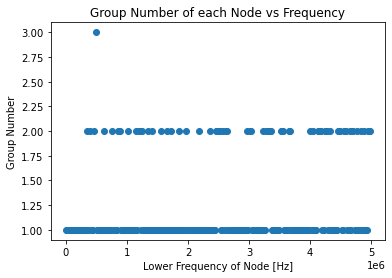

In [26]:
# plot regular k-means
plt.scatter([node.frequency_range[0] for node in wpt_df["node"]], reassigned_labels)
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [27]:
# apply PCA to training data
pca = PCA(n_components=3)#data_train.shape[1])
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters,**kmeans_params)
data_train_predict_pca = kmeans_pca.fit_predict(data_pca)

# convert centres back to regular feature space (energy, kurtosis, crest, etc.)
labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(
    pca.inverse_transform(kmeans_pca.cluster_centers_)
)
reassigned_pca_labels = assign_labels_entropy(centers_pca, labels_pca)

In [28]:
kmeans_pca.cluster_centers_

array([[-5.74843906e-01, -5.02309118e-02, -8.41169252e-03],
       [ 1.99630726e+00, -8.30297350e-02,  2.90150884e-02],
       [ 2.95796646e-02,  1.46784154e+01,  1.16550798e-02]])

<AxesSubplot:xlabel='principal component 1', ylabel='principal component 3'>

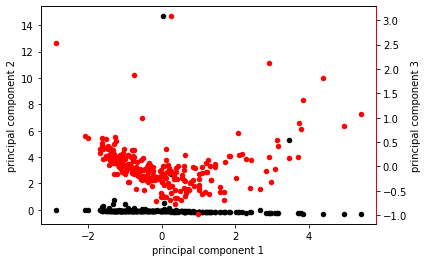

In [29]:
PC_df = pd.DataFrame(data = pca.transform(data_train_normalised)
             , columns = ['principal component 1', 'principal component 2', 'principal component 3'])

ax_pca_df1 = PC_df.plot.scatter(x='principal component 1',y='principal component 2', c='black')

ax_pca_df2 = ax_pca_df1.twinx()
ax_pca_df2.spines['right'].set_position(('axes', 1.0))
ax_pca_df2.spines['right'].set_edgecolor('red')
PC_df.plot.scatter(ax=ax_pca_df2, x='principal component 1',y='principal component 3', c='red')


### Plot PCA result

The group number vs frequency for each node is plotted again after PCA is applied.

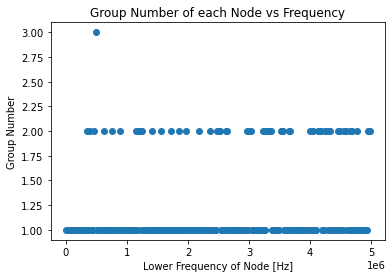

Eigenvectors:
['entropy', 'kurtosis', 'crest']
[[-0.04  0.71  0.71]
 [-1.   -0.04 -0.02]
 [-0.01  0.71 -0.71]]
Eigenvalues: [1.79 1.   0.22]


In [31]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node in wpt_df["node"]]
plt.scatter([node.frequency_range[0] for node in wpt_df["node"]], reassigned_pca_labels)
plt.tick_params
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print(classifying_metrics)
print(np.round(eigenvectors, 2))

print("Eigenvalues:", np.round(eigenvalues, 2))

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

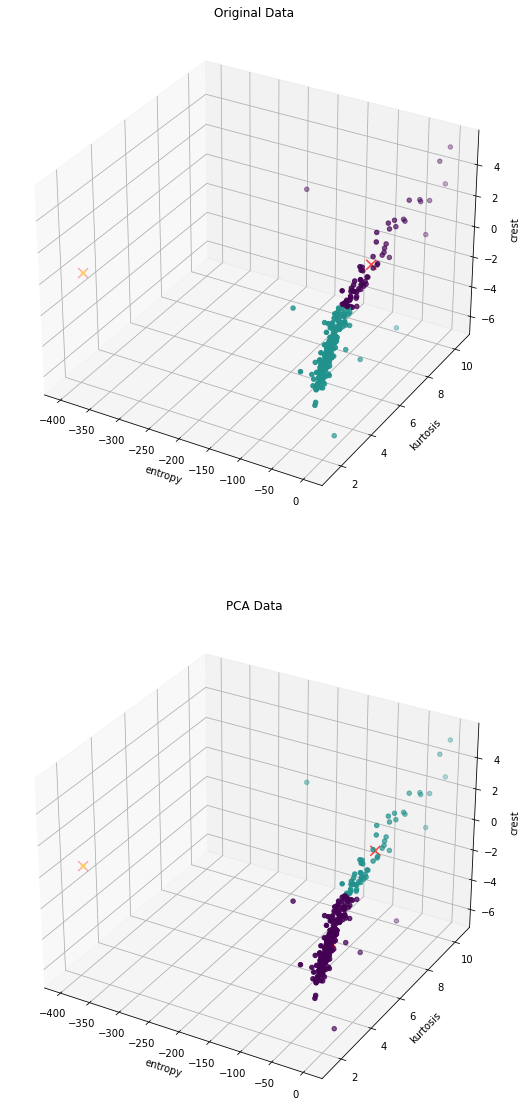

In [32]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

titles = ["Original Data", "PCA Data"]

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers
        labels_scatter = reassigned_labels
        color_map_labels = data_train_predict 
    else:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers_pca
        labels_scatter = labels_pca
        color_map_labels = data_train_predict_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(titles[i])

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number.

In [33]:
def plot_reconstructions(t_plot,wpt_recon_df, group=None):
    for i in range(wpt_recon_df.shape[0]):  # highest energy, kurtosis, etc.
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = wpt_recon_df["node"].values.tolist()[i].frequency_range
        ax[0].plot(
            t_plot,
            wpt_recon_df["inverse"].values.tolist()[i],
        )
        title = f"Reconstructed sub-band [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed sub-band [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(wpt_recon_df["fft"].values.tolist()[i]),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed sub-band")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()
        print(wpt_recon_df.iloc[i, 3:])

Change to group=reassign_pca_labels to display the groups assigned using PCA

In [ ]:
# plot_reconstructions(wpt_df, group=reassigned_labels)
# plot_reconstructions(wpt_recon_df, group=reassigned_pca_labels)

In [ ]:
THR_Factor = 0.1
harmonics_data = wpt_df[
    data_train["entropy"] < -1*THR_Factor * np.max(data_train["entropy"])
]
harmonics_data = harmonics_data.sort_values(by="entropy", ascending=False)

In [ ]:
transient_data = wpt_df[
    (data_train["kurtosis"] > THR_Factor * np.max(data_train["kurtosis"]))
    & (data_train["crest"] > THR_Factor * np.max(data_train["crest"]))
]
harmonics_data = harmonics_data.sort_values(by="kurtosis", ascending=False)

In [ ]:
plot_reconstructions(t_plot,harmonics_data, group=reassigned_labels)

In [ ]:
plot_reconstructions(t_plot,transient_data, group=reassigned_labels)

In [ ]:
harmonics_data["node"].values.tolist()[0].frequency_range

In [ ]:
harmonics_data.plot.bar()

In [ ]:
transient_data.plot.bar()
plt.show()

In [ ]:
plt.plot(np.sum(harmonics_data["inverse"]))
plt.plot(data-np.mean(data)) 

In [ ]:
plt.plot(np.sum(transient_data["inverse"]))
plt.plot(data-np.mean(data),'--') 